# Week 7 — Minute Bars from NASDAQ ITCH Tick Data

**ITCH Date:** October 30, 2019 (ITCH sample)

## Overview

This notebook generates **1-minute OHLCV bars** (and extended metrics) from raw NASDAQ
TotalView-ITCH tick data stored in an HDF5 file.

### Key insight

The ITCH HDF5 store indexes rows by integer **`stock_locate`** codes, _not_ ticker
symbols. We resolve tickers → locate codes via the `/R` (Stock Directory) table, then
use `where="stock_locate=<int>"` for efficient row selection.

### Trade messages used

| Table | Message | Direction |
|-------|---------|----------|
| **E** | Order Executed | from Add Order (A/F) join |
| **C** | Executed at Different Price | from Add Order join |
| **P** | Non-cross Trade | tick rule applied |

### Bar metrics

| Column | Description |
|--------|-------------|
| `open` | First trade price in the minute |
| `high` | Highest trade price |
| `low` | Lowest trade price |
| `close` | Last trade price |
| `volume` | Total shares traded |
| `vwap` | Volume-weighted average price |
| `trade_count` | Number of individual trades |
| `dollar_volume` | Notional value (Σ price × shares) |
| `n_at_ask` | Shares traded buyer-initiated |
| `n_at_bid` | Shares traded seller-initiated |

## 1. Imports & Setup

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.figsize": (14, 5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})

DATA_PATH = Path("data/itch.h5")
assert DATA_PATH.exists(), f"HDF5 file not found: {DATA_PATH}"
print(f"HDF5 file: {DATA_PATH}  ({DATA_PATH.stat().st_size / 1e9:.1f} GB)")

MARKET_OPEN_NS  = 9  * 3_600 * 1_000_000_000 + 30 * 60 * 1_000_000_000
MARKET_CLOSE_NS = 16 * 3_600 * 1_000_000_000
PRICE_SCALE     = 10_000
DATE            = "2019-10-30"

HDF5 file: data/itch.h5  (16.3 GB)


/home/charles/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 2. Explore the HDF5 Store

The ITCH parser stores each message type as a separate table inside the HDF5 file.

In [2]:
with pd.HDFStore(str(DATA_PATH), mode="r") as store:
    keys = store.keys()
    print("Tables:", keys)
    for k in keys:
        try:
            n = store.get_storer(k.lstrip("/")).nrows
            print(f"  {k:6s}  {n:15,.0f} rows")
        except Exception as e:
            print(f"  {k:6s}  (could not read nrows: {e})")

Tables: ['/A', '/B', '/C', '/D', '/E', '/F', '/H', '/I', '/J', '/L', '/P', '/Q', '/R', '/S', '/U', '/V', '/X', '/Y']
  /A          127,214,649 rows
  /B                    1 rows
  /C              129,729 rows
  /D          123,296,742 rows
  /E            7,316,703 rows
  /F            1,423,908 rows
  /H                8,897 rows
  /I            3,740,140 rows
  /J                    2 rows
  /L              214,865 rows
  /P            1,525,363 rows
  /Q               17,775 rows
  /R                8,887 rows
  /S                    6 rows
  /U           25,513,651 rows
  /V                    1 rows
  /X            3,568,735 rows
  /Y                9,025 rows


## 3. Stock Directory — symbol → `stock_locate`

ITCH message tables are indexed by an integer **`stock_locate`** code, not ticker
symbols. The `/R` table (Stock Directory) maps locate codes ↔ ticker strings.

In [3]:
def build_locate_map(h5path: Path = DATA_PATH) -> dict:
    """Return {ticker: stock_locate_int} from the /R table."""
    with pd.HDFStore(str(h5path), mode="r") as store:
        R = store["R"][["stock_locate", "stock"]]
    return dict(zip(R["stock"], R["stock_locate"].astype(int)))


_LOCATE_CACHE: dict = {}

def get_locate(symbol: str, h5path: Path = DATA_PATH) -> int | None:
    """Return the integer stock_locate for *symbol*, or None if not found."""
    if symbol in _LOCATE_CACHE:
        return _LOCATE_CACHE[symbol]
    with pd.HDFStore(str(h5path), mode="r") as store:
        R = store["R"][["stock_locate", "stock"]]
    row = R[R["stock"] == symbol]
    if row.empty:
        return None
    loc = int(row["stock_locate"].iloc[0])
    _LOCATE_CACHE[symbol] = loc
    return loc


# Preview the map
locate_map = build_locate_map()
print(f"{len(locate_map)} symbols in stock directory.  Sample:")
sample = dict(list(locate_map.items())[:10])
print(sample)

8886 symbols in stock directory.  Sample:
{'A': 1, 'AA': 2, 'AAAU': 3, 'AACG': 4, 'AADR': 5, 'AAL': 6, 'AAMC': 7, 'AAME': 8, 'AAN': 9, 'AAOI': 10}


## 4. Symbols

We'll generate bars for a basket of liquid names.  
Note: META was still trading as **FB** in October 2019, so it is excluded.

In [4]:
SYMBOLS = [
    "AAPL", "MSFT", "AMZN", "GOOGL",
    "TSLA", "NVDA", "JPM", "GS", "SPY",
]

# Check which are actually in the file
found     = [s for s in SYMBOLS if get_locate(s) is not None]
not_found = [s for s in SYMBOLS if get_locate(s) is None]
print(f"Found    : {found}")
print(f"Not found: {not_found}")

Found    : ['AAPL', 'MSFT', 'AMZN', 'GOOGL', 'TSLA', 'NVDA', 'JPM', 'GS', 'SPY']
Not found: []


## 5. Load Tick Data

We load three trade message types and join to Add Orders (A/F) for direction:

* **E** – *Order Executed*: join on `order_reference_number` → recover `buy_sell_indicator`
* **C** – *Executed at Different Price*: same join, price overridden
* **P** – *Non-cross Trade*: direction unknown → tick rule applied later

Prices are stored as integers (price × 10,000). Regular session: **09:30–16:00 ET**.

In [5]:
def _load_orders(locate: int, h5path: Path = DATA_PATH) -> pd.DataFrame:
    """Add Order messages (A + F) for *locate* — used to recover trade direction."""
    frames = []
    with pd.HDFStore(str(h5path), mode="r") as store:
        for mtype in ("A", "F"):
            try:
                df = store.select(mtype, where=f"stock_locate={locate}")
                if not df.empty:
                    frames.append(df[["order_reference_number", "buy_sell_indicator", "price"]])
            except Exception:
                pass
    if not frames:
        return pd.DataFrame()
    return pd.concat(frames, ignore_index=True).drop_duplicates("order_reference_number")


def load_trades(symbol: str, h5path: Path = DATA_PATH) -> pd.DataFrame:
    """
    Return executed trades for *symbol* with columns:
        timestamp (int ns), price (float $), shares (int),
        buy_sell_indicator (+1 buy / -1 sell / 0 unknown)
    Filtered to regular market hours.
    """
    locate = get_locate(symbol, h5path)
    if locate is None:
        print(f"  ⚠  {symbol} not found in stock directory.")
        return pd.DataFrame(columns=["timestamp", "price", "shares", "buy_sell_indicator"])

    orders = _load_orders(locate, h5path)
    frames = []

    # --- E: Order Executed ---------------------------------------------------
    with pd.HDFStore(str(h5path), mode="r") as store:
        try:
            e = store.select("E", where=f"stock_locate={locate}")
        except Exception:
            e = pd.DataFrame()
    if not e.empty and not orders.empty:
        merged = e.rename(columns={"executed_shares": "shares"}).merge(
            orders[["order_reference_number", "buy_sell_indicator", "price"]],
            on="order_reference_number", how="inner"
        )
        merged["price"] = merged["price"] / PRICE_SCALE
        frames.append(merged[["timestamp", "price", "shares", "buy_sell_indicator"]])

    # --- C: Executed at Different Price --------------------------------------
    with pd.HDFStore(str(h5path), mode="r") as store:
        try:
            c = store.select("C", where=f"stock_locate={locate}")
        except Exception:
            c = pd.DataFrame()
    if not c.empty and not orders.empty:
        merged = c.rename(columns={"execution_price": "price",
                                   "executed_shares": "shares"}).merge(
            orders[["order_reference_number", "buy_sell_indicator"]],
            on="order_reference_number", how="inner"
        )
        if "price" not in merged.columns:
            merged = c.rename(columns={"executed_shares": "shares"}).merge(
                orders[["order_reference_number", "buy_sell_indicator", "price"]],
                on="order_reference_number", how="inner"
            )
        merged["price"] = merged["price"] / PRICE_SCALE
        frames.append(merged[["timestamp", "price", "shares", "buy_sell_indicator"]])

    # --- P: Trade Message (non-cross) ----------------------------------------
    with pd.HDFStore(str(h5path), mode="r") as store:
        try:
            p = store.select("P", where=f"stock_locate={locate}")
        except Exception:
            p = pd.DataFrame()
    if not p.empty:
        p = p[["timestamp", "price", "shares", "buy_sell_indicator"]].copy()
        p["price"] = p["price"] / PRICE_SCALE
        frames.append(p)

    if not frames:
        return pd.DataFrame(columns=["timestamp", "price", "shares", "buy_sell_indicator"])

    df = pd.concat(frames, ignore_index=True)

    # Normalise timestamp → int nanoseconds
    if pd.api.types.is_timedelta64_dtype(df["timestamp"]):
        df["timestamp"] = df["timestamp"].dt.total_seconds().mul(1e9).astype("int64")
    else:
        df["timestamp"] = df["timestamp"].astype("int64")

    df = df[(df["timestamp"] >= MARKET_OPEN_NS) & (df["timestamp"] < MARKET_CLOSE_NS)]
    return df.sort_values("timestamp").reset_index(drop=True)

## 6. Trade Direction: Tick Rule

For **P** messages (direction unknown) we apply the **tick rule**:

> *Up-tick* (price ≥ previous) → buyer-initiated → traded **at ask** (+1)  
> *Down-tick* (price < previous) → seller-initiated → traded **at bid** (−1)

In [6]:
def apply_tick_rule(trades: pd.DataFrame) -> pd.DataFrame:
    df = trades.copy()
    mask = df["buy_sell_indicator"] == 0
    if mask.any():
        diff = df["price"].diff()
        df.loc[mask, "buy_sell_indicator"] = np.where(diff[mask] >= 0, 1, -1)
    df["buy_sell_indicator"] = (df["buy_sell_indicator"]
                                  .replace(0, np.nan).ffill().fillna(1).astype(int))
    return df

## 7. Build Minute Bars

Resample to 1-minute frequency using pandas `.resample("1min")`.

In [8]:
def build_minute_bars(trades: pd.DataFrame, date: str = DATE) -> pd.DataFrame:
    if trades.empty:
        return pd.DataFrame()
    trades = apply_tick_rule(trades)
    base   = pd.Timestamp(date)
    t = trades.copy()
    t["dt"] = base + pd.to_timedelta(t["timestamp"], unit="ns")
    t = t.set_index("dt").sort_index()

    t["dv"]     = t["price"] * t["shares"]
    t["at_ask"] = t["shares"].where(t["buy_sell_indicator"] ==  1, 0)
    t["at_bid"] = t["shares"].where(t["buy_sell_indicator"] == -1, 0)

    r = t.resample("1min")
    bars = pd.DataFrame({
        "open":          r["price"].first(),
        "high":          r["price"].max(),
        "low":           r["price"].min(),
        "close":         r["price"].last(),
        "volume":        r["shares"].sum(),
        "trade_count":   r["price"].count(),
        "dollar_volume": r["dv"].sum(),
        "n_at_ask":      r["at_ask"].sum(),
        "n_at_bid":      r["at_bid"].sum(),
    }).dropna(subset=["open"])

    bars["vwap"]          = bars["dollar_volume"] / bars["volume"]
    bars["volume"]        = bars["volume"].astype(int)
    bars["trade_count"]   = bars["trade_count"].astype(int)
    bars["n_at_ask"]      = bars["n_at_ask"].astype(int)
    bars["n_at_bid"]      = bars["n_at_bid"].astype(int)
    bars["dollar_volume"] = bars["dollar_volume"].round(2)
    bars.index.name = "minute"
    return bars

## 8. Run Pipeline

In [9]:
all_bars = {}

for sym in SYMBOLS:
    print(f"\n{'─'*52}")
    print(f"  {sym}")
    try:
        trades = load_trades(sym)
        if trades.empty:
            print(f"  ⚠  No trades found.")
            continue
        print(f"  Loaded {len(trades):,} ticks")
        bars = build_minute_bars(trades)
        print(f"  → {len(bars)} minute bars  |  "
              f"close: {bars['close'].iloc[-1]:.2f}  |  "
              f"vol: {bars['volume'].sum():,.0f}")
        all_bars[sym] = bars
    except Exception:
        import traceback; traceback.print_exc()

print("\nDone.")


────────────────────────────────────────────────────
  AAPL
  Loaded 58,701 ticks
  → 390 minute bars  |  close: 243.30  |  vol: 4,812,749

────────────────────────────────────────────────────
  MSFT
  Loaded 45,151 ticks
  → 390 minute bars  |  close: 144.56  |  vol: 4,137,455

────────────────────────────────────────────────────
  AMZN
  Loaded 18,213 ticks
  → 390 minute bars  |  close: 1780.00  |  vol: 515,871

────────────────────────────────────────────────────
  GOOGL
  Loaded 14,346 ticks
  → 384 minute bars  |  close: 1260.62  |  vol: 373,143

────────────────────────────────────────────────────
  TSLA
  Loaded 31,575 ticks
  → 390 minute bars  |  close: 314.86  |  vol: 1,899,562

────────────────────────────────────────────────────
  NVDA
  Loaded 18,665 ticks
  → 390 minute bars  |  close: 203.10  |  vol: 1,029,159

────────────────────────────────────────────────────
  JPM
  Loaded 12,983 ticks
  → 390 minute bars  |  close: 125.75  |  vol: 1,166,323

─────────────────────

## 9. Inspect Results

In [10]:
# Summary table
rows = []
for sym, bars in all_bars.items():
    rows.append({
        "symbol":            sym,
        "bars":              len(bars),
        "open":              bars["open"].iloc[0],
        "close":             bars["close"].iloc[-1],
        "high":              bars["high"].max(),does a phono step up transformer require a power source?
        "low":               bars["low"].min(),
        "total_volume":      bars["volume"].sum(),
        "dollar_volume":     bars["dollar_volume"].sum(),
        "avg_trade_count":   bars["trade_count"].mean().round(1),
    })

summary = pd.DataFrame(rows).set_index("symbol")
summary["dollar_volume"] = summary["dollar_volume"].map("{:,.0f}".format)
summary["total_volume"]  = summary["total_volume"].map("{:,.0f}".format)
summary

SyntaxError: ':' expected after dictionary key (4198153429.py, line 9)

In [11]:
# Peek at one symbol
sym = next(iter(all_bars))   # first available symbol
print(f"\n--- {sym} first 5 bars ---")
display(all_bars[sym].head())

print(f"\n--- {sym} last 5 bars ---")
display(all_bars[sym].tail())


--- AAPL first 5 bars ---


,open,high,low,close,volume,trade_count,dollar_volume,n_at_ask,n_at_bid,vwap
minute,,,,,,,,,,
2019-10-30 09:30:00,244.83,245.29,244.66,244.835,78731,714,19283753.46,40534,38197,244.932155
2019-10-30 09:31:00,244.81,244.81,244.50,244.770,31167,361,7626076.40,17150,14017,244.684326
2019-10-30 09:32:00,244.74,245.15,244.70,244.900,28473,414,6975092.58,17230,11243,244.972169
2019-10-30 09:33:00,244.93,244.95,244.73,244.740,16243,262,3976778.32,9882,6361,244.830285
2019-10-30 09:34:00,244.78,244.90,244.37,244.450,29686,265,7264584.16,13026,16660,244.714147



--- AAPL last 5 bars ---


,open,high,low,close,volume,trade_count,dollar_volume,n_at_ask,n_at_bid,vwap
minute,,,,,,,,,,
2019-10-30 15:55:00,243.190,243.23,243.08,243.13,44951,423,10929955.58,30266,14685,243.152668
2019-10-30 15:56:00,243.120,243.17,243.05,243.08,36502,395,8873862.92,24445,12057,243.106211
2019-10-30 15:57:00,243.075,243.16,243.05,243.06,59923,564,14566070.29,45829,14094,243.079791
2019-10-30 15:58:00,243.060,243.17,243.04,243.14,63524,599,15443203.88,45570,17954,243.108178
2019-10-30 15:59:00,243.140,243.52,243.10,243.30,122635,1204,29835745.04,79923,42712,243.288988


## 10. Visualise — AAPL

Four panels: price + VWAP, volume, trade count, and bid/ask imbalance.

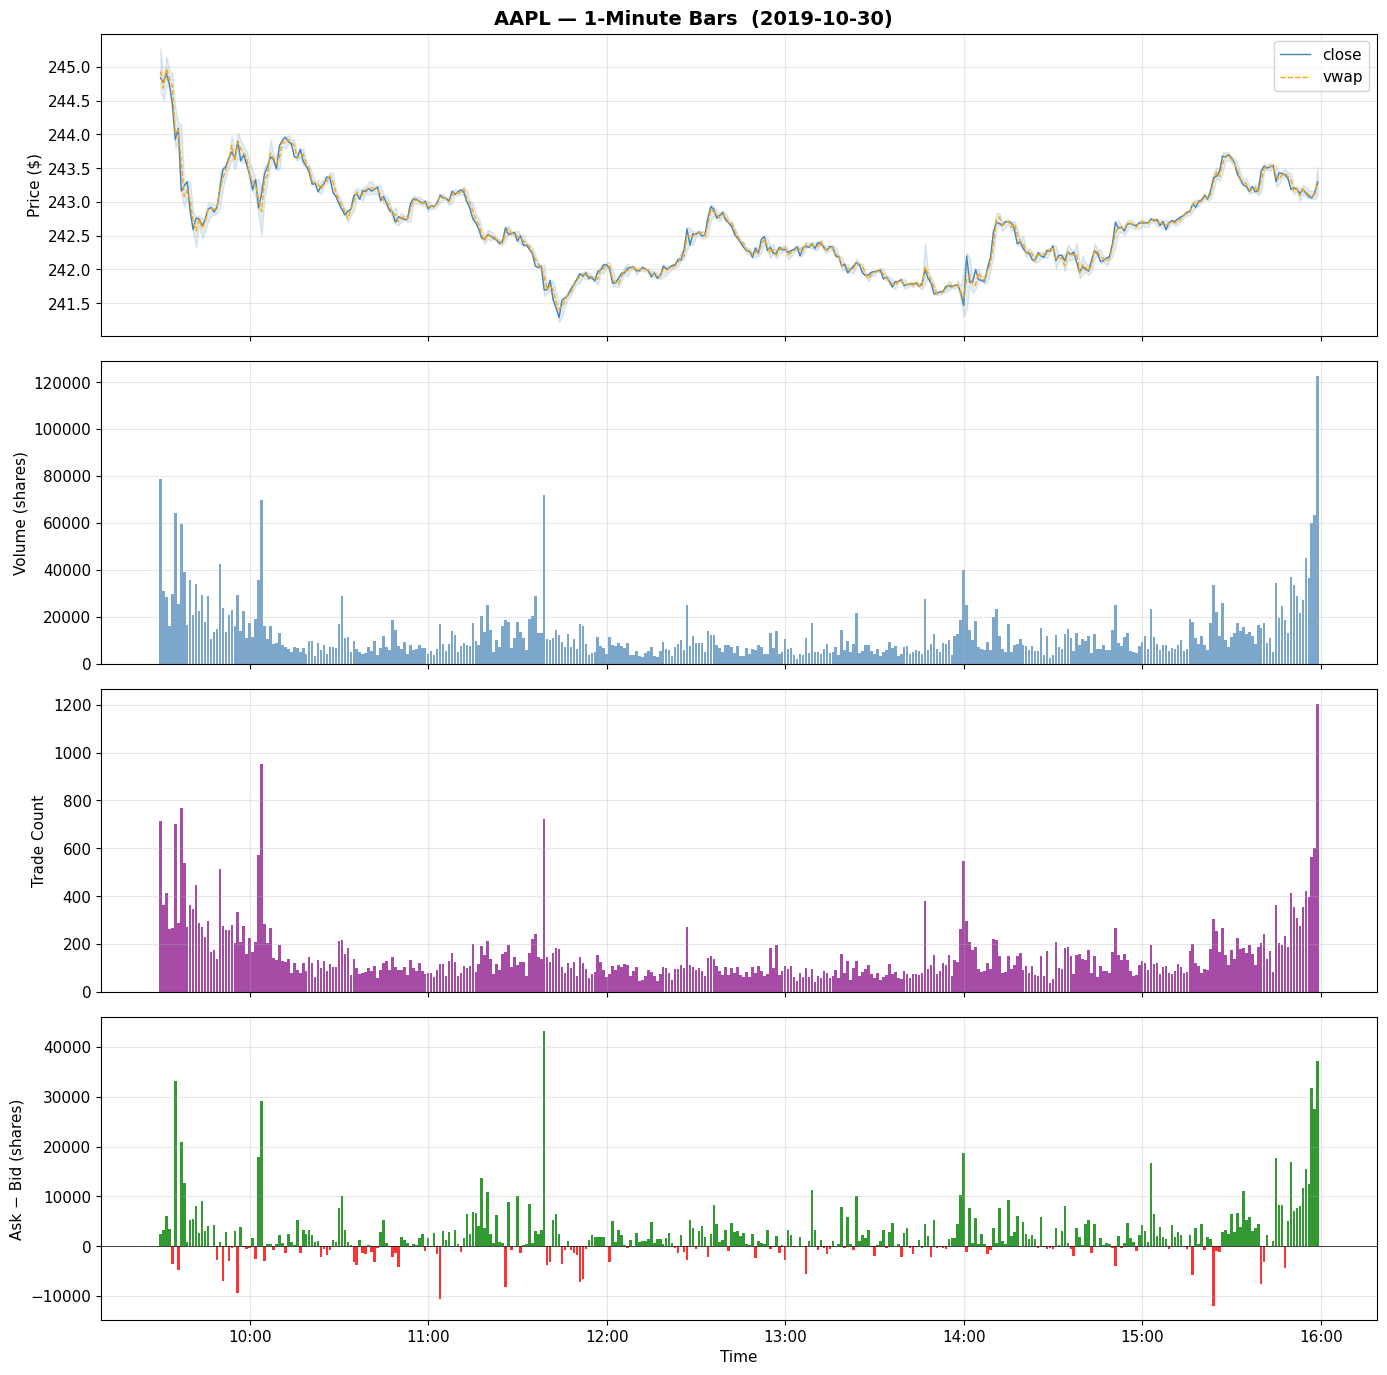

In [12]:
sym  = "AAPL"
bars = all_bars[sym]

fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=True)
fig.suptitle(f"{sym} — 1-Minute Bars  ({DATE})", fontsize=14, fontweight="bold")

# Price + VWAP
ax = axes[0]
ax.plot(bars.index, bars["close"], lw=1, color="steelblue", label="close")
ax.fill_between(bars.index, bars["low"], bars["high"], alpha=0.15, color="steelblue")
ax.plot(bars.index, bars["vwap"],  lw=1, color="orange", label="vwap", linestyle="--")
ax.set_ylabel("Price ($)")
ax.legend(loc="upper right")

# Volume
ax = axes[1]
ax.bar(bars.index, bars["volume"], width=0.0006, color="steelblue", alpha=0.7)
ax.set_ylabel("Volume (shares)")

# Trade count
ax = axes[2]
ax.bar(bars.index, bars["trade_count"], width=0.0006, color="purple", alpha=0.7)
ax.set_ylabel("Trade Count")

# Bid / Ask imbalance
ax = axes[3]
imbalance = bars["n_at_ask"] - bars["n_at_bid"]
colors = ["green" if v >= 0 else "red" for v in imbalance]
ax.bar(bars.index, imbalance, width=0.0006, color=colors, alpha=0.8)
ax.axhline(0, color="black", lw=0.5)
ax.set_ylabel("Ask − Bid (shares)")
ax.set_xlabel("Time")

for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

plt.tight_layout()
plt.savefig("aapl_minute_bars.png", dpi=150)
plt.show()

## 11. Save Results

In [13]:
# Save CSVs
out_dir = Path("data/minute_bars")
out_dir.mkdir(parents=True, exist_ok=True)

for sym, bars in all_bars.items():
    bars.to_csv(out_dir / f"{sym}_1min.csv")
    print(f"  Saved {sym}")

print(f"\nAll bars saved to: {out_dir.resolve()}")

  Saved AAPL
  Saved MSFT
  Saved AMZN
  Saved GOOGL
  Saved TSLA
  Saved NVDA
  Saved JPM
  Saved GS
  Saved SPY

All bars saved to: /home/charles/Columbia/courses/IEORE4733_2026/Notes/Week_7/data/minute_bars


In [14]:
# Optional: save HDF5
out_h5 = Path("data/minute_bars.h5")

with pd.HDFStore(str(out_h5), mode="w", complevel=5, complib="blosc") as store:
    for sym, bars in all_bars.items():
        store.put(f"minute_bars/{sym}", bars, format="table", data_columns=True)
        print(f"  ✅  {sym} → {out_h5}:/minute_bars/{sym}")

print(f"\nAll bars saved to {out_h5}")

  ✅  AAPL → data/minute_bars.h5:/minute_bars/AAPL
  ✅  MSFT → data/minute_bars.h5:/minute_bars/MSFT
  ✅  AMZN → data/minute_bars.h5:/minute_bars/AMZN
  ✅  GOOGL → data/minute_bars.h5:/minute_bars/GOOGL
  ✅  TSLA → data/minute_bars.h5:/minute_bars/TSLA
  ✅  NVDA → data/minute_bars.h5:/minute_bars/NVDA
  ✅  JPM → data/minute_bars.h5:/minute_bars/JPM
  ✅  GS → data/minute_bars.h5:/minute_bars/GS
  ✅  SPY → data/minute_bars.h5:/minute_bars/SPY

All bars saved to data/minute_bars.h5
